# Exploratory Data Analysis

We explore the 2016 building energy benchmarking data of Seattle. We select the non-residential properties and clean them before the feature engineering (notebook 02) and the modeling (notebook 03).

## 0. Setup

Imports, plot style and raw data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Matplotlib style, set once for all the figures
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": "#e5e5e5",
        "legend.frameon": False,
    }
)

# Load the dataset
building_consumption = pd.read_csv("../data/raw/2016_Building_Energy_Benchmarking.csv")

## 1. Scope and target

We predict the total energy use of **non-residential** properties. The target is `SiteEnergyUse(kBtu)`, the energy consumed on site in one year.

The file mixes multifamily housing with non-residential properties, so we filter it in section 3.

Many columns are computed from the energy bills: energy use intensity (EUI), electricity, gas, steam, emissions. We cannot use them as features. A new property has no bill yet, so they would leak the target.

In [2]:
# Display the first few rows of the dataset
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [3]:
building_consumption.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

In [4]:
building_consumption.describe()

,OSEBuildingID,DataYear,ZipCode,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,...,SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),Comments,TotalGHGEmissions,GHGEmissionsIntensity
count,3376.000000,3376.0,3360.000000,3376.000000,3376.000000,3376.000000,3376.000000,3368.000000,3376.000000,3.376000e+03,...,3.371000e+03,3.370000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,3.367000e+03,0.0,3367.000000,3367.000000
mean,21208.991114,2016.0,98116.949107,4.439277,47.624033,-122.334795,1968.573164,1.106888,4.709123,9.483354e+04,...,5.403667e+06,5.276726e+06,2.745959e+05,1.086639e+06,3.707612e+06,1.368505e+04,1.368505e+06,NaN,119.723971,1.175916
std,12223.757015,0.0,18.615205,2.120625,0.047758,0.027203,33.088156,2.108402,5.494465,2.188376e+05,...,2.161063e+07,1.593879e+07,3.912173e+06,4.352478e+06,1.485066e+07,6.709781e+04,6.709781e+06,NaN,538.832227,1.821452
min,1.000000,2016.0,98006.000000,1.000000,47.499170,-122.414250,1900.000000,0.000000,0.000000,1.128500e+04,...,0.000000e+00,0.000000e+00,0.000000e+00,-3.382680e+04,-1.154170e+05,0.000000e+00,0.000000e+00,NaN,-0.800000,-0.020000
25%,19990.750000,2016.0,98105.000000,3.000000,47.599860,-122.350662,1948.000000,1.000000,2.000000,2.848700e+04,...,9.251286e+05,9.701822e+05,0.000000e+00,1.874229e+05,6.394870e+05,0.000000e+00,0.000000e+00,NaN,9.495000,0.210000
50%,23112.000000,2016.0,98115.000000,4.000000,47.618675,-122.332495,1975.000000,1.000000,4.000000,4.417500e+04,...,1.803753e+06,1.904452e+06,0.000000e+00,3.451299e+05,1.177583e+06,3.237538e+03,3.237540e+05,NaN,33.920000,0.610000
75%,25994.250000,2016.0,98122.000000,7.000000,47.657115,-122.319407,1997.000000,1.000000,5.000000,9.099200e+04,...,4.222455e+06,4.381429e+06,0.000000e+00,8.293178e+05,2.829632e+06,1.189033e+04,1.189034e+06,NaN,93.940000,1.370000
max,50226.000000,2016.0,98272.000000,7.000000,47.733870,-122.220966,2015.000000,111.000000,99.000000,9.320156e+06,...,8.739237e+08,4.716139e+08,1.349435e+08,1.925775e+08,6.570744e+08,2.979090e+06,2.979090e+08,NaN,16870.980000,34.090000


### Missing values

In [5]:
# Share of missing values per column (only columns with at least one NA)
missing = building_consumption.isna().mean().sort_values(ascending=False)
missing[missing > 0].mul(100).round(1).rename("% missing")

Comments                           100.0
Outlier                             99.1
YearsENERGYSTARCertified            96.5
ThirdLargestPropertyUseType         82.3
ThirdLargestPropertyUseTypeGFA      82.3
SecondLargestPropertyUseType        50.3
SecondLargestPropertyUseTypeGFA     50.3
ENERGYSTARScore                     25.0
LargestPropertyUseTypeGFA            0.6
LargestPropertyUseType               0.6
ZipCode                              0.5
ListOfAllPropertyUseTypes            0.3
Electricity(kWh)                     0.3
SourceEUIWN(kBtu/sf)                 0.3
GHGEmissionsIntensity                0.3
TotalGHGEmissions                    0.3
NaturalGas(therms)                   0.3
SteamUse(kBtu)                       0.3
NaturalGas(kBtu)                     0.3
SourceEUI(kBtu/sf)                   0.3
Electricity(kBtu)                    0.3
NumberofBuildings                    0.2
SiteEUI(kBtu/sf)                     0.2
SiteEnergyUseWN(kBtu)                0.2
SiteEUIWN(kBtu/s

Several columns are almost empty: `Comments`, `YearsENERGYSTARCertified`, the third use type, the city's outlier flag. The column triage below drops them.

## 2. Column triage

We sort the 46 columns into four groups:

1. The target.
2. Key features: physical or structural properties, known without any energy bill.
3. Leakage: computed from the energy use, so we drop them.
4. Useless or redundant: constant, empty, identifiers, free text or duplicated information.

A few columns are kept only as feature-engineering candidates (`FE_CANDIDATES`), such as the use types.

### Is `PropertyGFATotal` redundant?

We check whether the total area is the sum of the building and parking areas.

In [6]:
gfa_total_match_rate = building_consumption.eval(
    "PropertyGFATotal == `PropertyGFABuilding(s)` + PropertyGFAParking"
).mean()
print(f"Match rate for PropertyGFATotal: {gfa_total_match_rate:.2%}")

Match rate for PropertyGFATotal: 100.00%


#### Decision

We drop `PropertyGFATotal`. It equals `PropertyGFABuilding(s)` + `PropertyGFAParking` on every row. We keep the two parts, because a square foot of parking uses far less energy than a square foot of building.

### Are the areas by use reliable?

`LargestPropertyUseTypeGFA` and `SecondLargestPropertyUseTypeGFA` give the area of each use. We check two things on the full file. Can they exceed the property area? Do they repeat the building area?

In [7]:
total_area = building_consumption["PropertyGFATotal"]
building_area = building_consumption["PropertyGFABuilding(s)"]

use_area_checks = {}
for col in ["LargestPropertyUseTypeGFA", "SecondLargestPropertyUseTypeGFA"]:
    use_area = building_consumption[col]
    use_area_checks[col] = {
        "rows with a value": use_area.notna().sum(),
        "% above PropertyGFATotal": (use_area > total_area)[use_area.notna()].mean()
        * 100,
        "Pearson vs building area": use_area.corr(building_area),
    }

pd.DataFrame(use_area_checks).T.round(2)

,rows with a value,% above PropertyGFATotal,Pearson vs building area
LargestPropertyUseTypeGFA,3356.0,10.1,0.98
SecondLargestPropertyUseTypeGFA,1679.0,0.3,0.79


#### Decision

We drop both area columns and keep the use-type categories.

- `LargestPropertyUseTypeGFA` exceeds the whole property area in 10% of the rows, which is impossible. It is also almost the building area itself (Pearson 0.98).
- `SecondLargestPropertyUseTypeGFA` is less redundant (Pearson 0.79). We drop it because it is declarative, like the first one. The useful information, the type of the secondary use, stays in `SecondLargestPropertyUseType`.

### Weather-normalized or raw target?

The file gives two versions of the energy use: the raw one, and one normalized for the weather of the year. We compare them.

In [8]:
# Compare the two versions
raw_wn = building_consumption[["SiteEnergyUse(kBtu)", "SiteEnergyUseWN(kBtu)"]].dropna()
raw, wn = raw_wn.iloc[:, 0], raw_wn.iloc[:, 1]

# Pearson is sensitive to extreme values: check it without the largest row
largest = raw.idxmax()
no_max = raw_wn.drop(largest)
print(
    f"Largest row: {building_consumption.loc[largest, 'PropertyName']} ({raw[largest]:,.0f} kBtu)"
)
print(
    f"Pearson : {raw.corr(wn):.3f}  (without the largest row: {no_max.iloc[:, 0].corr(no_max.iloc[:, 1]):.3f})"
)

Largest row: University of Washington - Seattle Campus (873,923,712 kBtu)
Pearson : 0.715  (without the largest row: 0.997)


Pearson between the two versions is only 0.715. A single row explains it, the University of Washington campus. Without it, Pearson jumps to 0.997: the two versions follow each other almost perfectly. Pearson is sensitive to extreme values, and this campus is one (step 5 drops it).

#### Decision

Since the two versions are so close, the choice matters little for the model. We keep the raw `SiteEnergyUse(kBtu)` as the target, because we want to predict what a property actually consumes. The weather-normalized value is itself the output of a model run by the city. `SiteEnergyUseWN(kBtu)` stays out of the features (leakage).

### Selected columns

Every column, with its group and the reason for the decision.

In [9]:
TARGET = "SiteEnergyUse(kBtu)"

# Key features: physical or structural properties, known without any energy bill
KEY_FEATURES = {
    "PropertyGFABuilding(s)": "Floor area of the heated/cooled buildings (excludes parking)",
    "PropertyGFAParking": "Parking area: low energy use per sq ft, so it dilutes the total",
    "PrimaryPropertyType": "Coarser property category, fewer levels than LargestPropertyUseType",
    "NumberofFloors": "Building height, correlated with size and HVAC needs",
    "NumberofBuildings": "Campus vs single building",
    "YearBuilt": "candidate for a construction-period feature",
    "Neighborhood": "Cleaner than ZipCode, 13 levels after cleaning, OneHot",
    "Latitude": "Location (microclimate, downtown density)",
    "Longitude": "Location (microclimate, downtown density)",
}

# Feature-engineering candidates: may help, but need a decision
FE_CANDIDATES = {
    "LargestPropertyUseType": "Main activity (office, hospital, warehouse...): EUI varies hugely by use",
    "SecondLargestPropertyUseType": "Secondary use (NaN = single-use property)",
    "ListOfAllPropertyUseTypes": (
        "All declared uses, including minor ones hidden by PrimaryPropertyType (e.g. a data center "
        "inside an office): source for energy-intensive use flags"
    ),
}

# Leakage: computed from the target (or from its components), never use as features
LEAKAGE = {
    "SiteEnergyUseWN(kBtu)": "Weather-normalized version of the target",
    "SiteEUI(kBtu/sf)": "Target / floor area",
    "SiteEUIWN(kBtu/sf)": "Weather-normalized EUI",
    "SourceEUI(kBtu/sf)": "Source energy / floor area",
    "SourceEUIWN(kBtu/sf)": "Weather-normalized source EUI",
    "Electricity(kWh)": "Component of the target",
    "Electricity(kBtu)": "Component of the target (same as kWh, other unit)",
    "NaturalGas(therms)": "Component of the target",
    "NaturalGas(kBtu)": "Component of the target (same as therms, other unit)",
    "SteamUse(kBtu)": "Component of the target",
    "TotalGHGEmissions": "Computed from energy consumption",
    "GHGEmissionsIntensity": "Computed from energy consumption",
    "ENERGYSTARScore": (
        "1-100 percentile rank of the property's measured energy use (EUI) against similar "
        "properties: it can only be computed once the consumption is known. Also 25% missing"
    ),
}

# Useless: no predictive information
USELESS_OR_REDUNDANT = {
    "BuildingType": "Only used to filter non-residential properties; redundant with PrimaryPropertyType once filtered",
    "Comments": "100% empty",
    "YearsENERGYSTARCertified": "96% empty",
    "ThirdLargestPropertyUseType": "82% empty",
    "ThirdLargestPropertyUseTypeGFA": "82% empty",
    "Outlier": "99% empty: only used to flag rows to drop",
    "DataYear": "Constant (2016)",
    "City": "Constant (Seattle)",
    "State": "Constant (WA)",
    "OSEBuildingID": "Row identifier",
    "PropertyName": "Free text identifier",
    "Address": "Free text identifier, near unique",
    "TaxParcelIdentificationNumber": "Identifier",
    "ZipCode": "Redundant with Neighborhood / Lat-Long",
    "CouncilDistrictCode": "Redundant with Neighborhood / Lat-Long",
    "DefaultData": "Redundant with ComplianceStatus (True <=> 'Error - Correct Default Data'), not used",
    "ComplianceStatus": "Quality flag, only used to filter rows (default data = unreliable features)",
    "PropertyGFATotal": "Redundant: always = PropertyGFABuilding(s) + PropertyGFAParking",
    "LargestPropertyUseTypeGFA": "Unreliable (can exceed the property area) and redundant with the building / parking areas",
    "SecondLargestPropertyUseTypeGFA": "Unreliable (can exceed the property area) and redundant with the building / parking areas",
}

# Safety net: every column must be classified exactly once
classified = [TARGET, *KEY_FEATURES, *FE_CANDIDATES, *LEAKAGE, *USELESS_OR_REDUNDANT]
print("Unclassified:", set(building_consumption.columns) - set(classified))
print("Duplicated:", {c for c in classified if classified.count(c) > 1})

# Overview table
groups = {
    "key": KEY_FEATURES,
    "fe_candidate": FE_CANDIDATES,
    "leakage": LEAKAGE,
    "useless_or_redundant": USELESS_OR_REDUNDANT,
}
triage = pd.DataFrame(
    [
        (group, col, reason)
        for group, cols in groups.items()
        for col, reason in cols.items()
    ],
    columns=["group", "column", "reason"],
)
triage

Unclassified: set()
Duplicated: set()


,group,column,reason
0,key,PropertyGFABuilding(s),Floor area of the heated/cooled buildings (exc...
1,key,PropertyGFAParking,"Parking area: low energy use per sq ft, so it ..."
2,key,PrimaryPropertyType,"Coarser property category, fewer levels than L..."
3,key,NumberofFloors,"Building height, correlated with size and HVAC..."
4,key,NumberofBuildings,Campus vs single building
5,key,YearBuilt,candidate for a construction-period feature
6,key,Neighborhood,"Cleaner than ZipCode, 13 levels after cleaning..."
7,key,Latitude,"Location (microclimate, downtown density)"
8,key,Longitude,"Location (microclimate, downtown density)"
9,fe_candidate,LargestPropertyUseType,"Main activity (office, hospital, warehouse...)..."


## 3. Filtering and cleaning

We apply row-level rules, in order. Each step prints the number of rows it removes.

1. Keep non-residential properties only.
2. Drop the outliers flagged by the city.
3. Drop invalid targets (missing or zero energy use).
4. Drop reports based on default data.
5. Drop the University of Washington campus.
6. Fix or drop impossible values, checked against the city's records.
7. Harmonize the `Neighborhood` labels.

In [10]:
df = building_consumption.copy()
print(f"{'start':<35}{len(df):>6}")


def keep(df, mask, label):
    """Keep rows where mask is True and report how many were removed."""
    out = df[mask]
    print(f"{label:<35}{len(out):>6}  (-{len(df) - len(out)})")
    return out

start                                3376


### Step 1 – Non-residential only

`BuildingType` removes most of the housing, but a few rows labeled non-residential are still housing by their main use.

In [11]:
df = keep(
    df, ~df["BuildingType"].str.contains("Multifamily"), "non-residential building type"
)

multifamily_use = df["PrimaryPropertyType"].str.contains("Multifamily") | (
    df["LargestPropertyUseType"] == "Multifamily Housing"
)
display(
    df[multifamily_use]
    .groupby(["BuildingType", "PrimaryPropertyType", "LargestPropertyUseType"])
    .size()
    .rename("rows")
)

non-residential building type        1668  (-1708)


BuildingType    PrimaryPropertyType   LargestPropertyUseType
Campus          Low-Rise Multifamily  Multifamily Housing       1
NonResidential  Low-Rise Multifamily  Multifamily Housing       2
                Mixed Use Property    Multifamily Housing       9
Name: rows, dtype: int64

#### Decision

We drop them. They are housing (low-rise multifamily, or mixed use where housing is the largest use), outside the scope.

In [12]:
df = keep(df, ~multifamily_use, "no multifamily use left")

no multifamily use left              1656  (-12)


### Step 2 – Outliers flagged by the city

The city flags reports whose EUI is extremely low or high for their property type.

In [13]:
display(df["Outlier"].value_counts())
display(
    df.loc[
        df["Outlier"] == "High outlier",
        [
            "PropertyName",
            "PrimaryPropertyType",
            "ListOfAllPropertyUseTypes",
            "SiteEUI(kBtu/sf)",
            "ComplianceStatus",
        ],
    ]
)

Outlier
Low outlier     14
High outlier     2
Name: count, dtype: int64

,PropertyName,PrimaryPropertyType,ListOfAllPropertyUseTypes,SiteEUI(kBtu/sf),ComplianceStatus
226,Second And Spring Building,Large Office,"Data Center, Office, Parking",297.399994,Non-Compliant
517,401 Elliott Ave West,Large Office,"Data Center, Office, Parking",311.700012,Non-Compliant


#### Decision

We drop them, as the city sees them as a sign of errors in the report.

The flag is a threshold per property type, so it does not always mean an error. The two high outliers are offices that also host a data center. Their energy use is probably real, but step 4 would remove them anyway. The low outliers look like incomplete reports or nearly empty buildings.

This also shows that `PrimaryPropertyType` can hide an energy-intensive use. This is why we keep `ListOfAllPropertyUseTypes` as a feature-engineering candidate.

In [14]:
df = keep(df, df["Outlier"].isna(), "not flagged as outlier")

not flagged as outlier               1640  (-16)


### Step 3 – Valid target

We cannot learn from a property with no energy use. The `ComplianceStatus` of these rows shows that the reports were incomplete anyway.

In [15]:
valid_target = df[TARGET].notna() & (df[TARGET] > 0)
display(df.loc[~valid_target, "ComplianceStatus"].value_counts())
df = keep(df, valid_target, "target > 0")

ComplianceStatus
Missing Data                    14
Non-Compliant                    3
Error - Correct Default Data     1
Name: count, dtype: int64

target > 0                           1622  (-18)


### Step 4 – Default data

Some reports were filled in with default values when the owner did not provide the information.

In [16]:
display(pd.crosstab(df["ComplianceStatus"], df["DefaultData"]))

DefaultData,False,True
ComplianceStatus,,
Compliant,1537,0
Error - Correct Default Data,0,85


#### Decision

We keep only `Compliant` reports. The other rows are exactly the ones with `DefaultData = True`. The city considers reports with default values as inaccurate ([source](https://www.seattle.gov/documents/departments/ose/eb_default_data_com_19.pdf)).

In [17]:
df = keep(df, df["ComplianceStatus"] == "Compliant", "compliant")

compliant                            1537  (-85)


### Step 5 – Extreme target

The five largest consumers.

In [18]:
df.nlargest(5, TARGET)[["OSEBuildingID", "PropertyName", "NumberofBuildings", TARGET]]

,OSEBuildingID,PropertyName,NumberofBuildings,SiteEnergyUse(kBtu)
3274,49967,University of Washington - Seattle Campus,111.0,873923712.0
35,43,Plant 2 Site,1.0,448385312.0
170,276,Harborview Medical Center,9.0,293090784.0
618,828,Swedish First Hill,7.0,291614432.0
558,753,WestinBuilding,1.0,274682208.0


#### Decision

We drop the University of Washington campus. Its energy use is almost twice the second highest, and it groups 111 buildings. It is a small town rather than a typical property, so it is outside what we want to predict.

In [19]:
df = keep(df, df["OSEBuildingID"] != 49967, "not the UW campus")

not the UW campus                    1536  (-1)


### Step 6 – Impossible and inconsistent values

We look for values that cannot be right: 0 floors or 0 buildings, an extreme number of floors, extreme area by floor, and building areas below the 20,000 sq ft threshold of the city's benchmarking program.

In [20]:
cols = [
    "OSEBuildingID",
    "PropertyName",
    "NumberofFloors",
    "NumberofBuildings",
    "PropertyGFABuilding(s)",
    "PropertyGFAParking",
    "SiteEUI(kBtu/sf)",
    TARGET,
]
display(df.loc[df["NumberofFloors"] == 0, cols])
print(f"Rows with 0 buildings: {(df['NumberofBuildings'] == 0).sum()}")

,OSEBuildingID,PropertyName,NumberofFloors,NumberofBuildings,PropertyGFABuilding(s),PropertyGFAParking,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu)
166,267,Grand Hyatt Seattle,0,1.0,934292,0,117.900002,65047284.00
487,656,Arnold Pavilion,0,1.0,225982,0,102.699997,20560622.00
488,657,2200 Westlake - SEDO,0,0.0,516407,0,76.300003,39403320.00
564,758,Pacific Place,0,1.0,947987,0,62.299999,46510960.00
1754,23311,HART First Hill LLC,0,1.0,274568,0,111.000000,25311526.00
1993,24086,(ID#24086)Campus1:KC Metro Transit Atlantic Ce...,0,10.0,230971,0,91.000000,21022288.00
3130,40028,Sandpoint #5,0,1.0,384772,0,36.700001,15206762.00
3131,40031,Sandpoint #25,0,1.0,30287,0,78.199997,2193115.00
3132,40034,Sandpoint #29,0,1.0,21931,0,124.000000,3947209.25
3168,49705,Magnuson,0,8.0,502030,0,32.700001,18470340.00


Rows with 0 buildings: 52


The properties with 0 floors are large buildings with a real energy use (Grand Hyatt, Pacific Place...). Here, 0 means a missing value, not a wrong row.

At the other end, one property has an extreme number of floors:

In [21]:
df.loc[df["NumberofFloors"] == df["NumberofFloors"].max(), cols]

,OSEBuildingID,PropertyName,NumberofFloors,NumberofBuildings,PropertyGFABuilding(s),PropertyGFAParking,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu)
1359,21611,Seattle Chinese Baptist Church,99,1.0,21948,0,14.9,326001.1875


The Seattle Chinese Baptist Church is listed with 99 floors, for 21,948 sq ft and a low energy use. Google Street View shows a single-floor building.

"Entire Campus", at 901 12th Avenue, reports 2.2 million sq ft on 2 floors in a single building. That is about 1.1 million sq ft per floor, which is not physically possible. We found this row while building the floor-area-per-floor feature (notebook 02).

The benchmarking program only applies to buildings over 20,000 sq ft, parking excluded. A smaller building area is therefore suspicious.

In [22]:
display(df.loc[df["PropertyGFABuilding(s)"] < 20000, cols])

,OSEBuildingID,PropertyName,NumberofFloors,NumberofBuildings,PropertyGFABuilding(s),PropertyGFAParking,SiteEUI(kBtu/sf),SiteEnergyUse(kBtu)
432,592,SEATTLE 1ST AVE GAR,1,1.0,11440,41600,34.400002,1.770028e+06
830,19928,Olympic Sculpture Park,2,1.0,10925,22867,241.100006,2.547848e+06
1109,20885,Ballard Center,2,1.0,3636,31000,337.500000,1.214872e+07
1175,21178,6 Nick,3,1.0,19497,6922,40.700001,1.074989e+06
1269,21398,Clements Rice Building (Block 38W) - SEDO,3,1.0,16200,12180,48.400002,1.372213e+06
1288,21459,Century,4,1.0,17824,7308,55.599998,5.647542e+05
1534,22312,The Seattle Public Library - Ballard Branch,1,1.0,15000,15576,84.699997,1.533246e+06
1877,23673,2300 Eastlake,3,1.0,17956,7956,38.500000,6.667403e+05
2246,24955,3420/3430 E. Marginal Way Whse,1,1.0,16300,0,2.300000,1.501678e+05
2380,25452,Chandler's Cove - SEDO,2,1.0,19237,15402,359.700012,1.548068e+07


Three properties stand out:

- Ballard Center has 3,636 sq ft of building area. The city's current dataset gives 34,636 sq ft every year since 2015, so a digit is missing.
- 3420/3430 E. Marginal Way has two warehouses, but only the smaller one was counted. The sum, 65,164 sq ft, is exactly the declared area of its main use.
- Chandler's Cove has a very high EUI, but its areas match the city's data. Its main use is restaurants, one of the most energy-intensive types.

The other properties below the threshold are mostly city facilities (fire stations, community centers, libraries, pools) with a plausible EUI.

#### Decision

- 0 floors becomes a missing value. The modeling pipeline will impute it with the median, learned on the training set only.
- 0 buildings becomes 1. This is a business rule, not a statistic: a reported property has at least one building. It can be applied before the split.
- The Seattle Chinese Baptist Church gets 1 floor instead of 99.
- "Entire Campus" is dropped. Its reported structure contradicts the city's records. The corrected property would be a 39-building campus, an extreme case like the UW campus (step 5).
- Ballard Center gets 34,636 sq ft instead of 3,636.
- 3420/3430 E. Marginal Way gets 65,164 sq ft and 2 buildings.
- Chandler's Cove and the other small properties are kept as is.

In [23]:
df["NumberofFloors"] = df["NumberofFloors"].replace(0, np.nan)
df["NumberofBuildings"] = df["NumberofBuildings"].replace(0, 1)

# Seattle Chinese Baptist Church
df.loc[df["OSEBuildingID"] == 21611, "NumberofFloors"] = 1
# Campus at 901 12th Avenue
df = keep(df, df["OSEBuildingID"] != 22062, "not the Campus at 901 12th Avenue")
# Ballard Center
df.loc[df["OSEBuildingID"] == 20885, "PropertyGFABuilding(s)"] = 34636
# 3420/3430 E. Marginal Way
df.loc[
    df["OSEBuildingID"] == 24955, ["PropertyGFABuilding(s)", "NumberofBuildings"]
] = [65164, 2]

not the Campus at 901 12th Avenue    1535  (-1)


### Step 7 – Location

We harmonize the neighborhood labels and check the coordinates on a map.

In [24]:
print(sorted(df["Neighborhood"].unique()))

['BALLARD', 'Ballard', 'CENTRAL', 'Central', 'DELRIDGE', 'DELRIDGE NEIGHBORHOODS', 'DOWNTOWN', 'Delridge', 'EAST', 'GREATER DUWAMISH', 'LAKE UNION', 'MAGNOLIA / QUEEN ANNE', 'NORTH', 'NORTHEAST', 'NORTHWEST', 'North', 'Northwest', 'SOUTHEAST', 'SOUTHWEST']


#### Decision

We use upper case everywhere (`North` → `NORTH`) and drop the stray suffix (`DELRIDGE NEIGHBORHOODS` → `DELRIDGE`).

In [25]:
df["Neighborhood"] = (
    df["Neighborhood"].str.upper().str.replace(" NEIGHBORHOODS", "", regex=False)
)
print(f"\nAfter cleaning: {df['Neighborhood'].nunique()} neighborhoods")


After cleaning: 13 neighborhoods


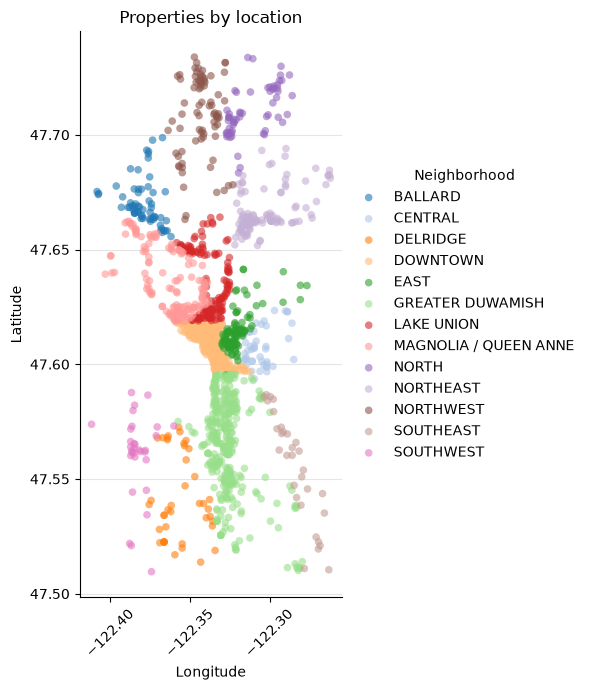

In [26]:
fig, ax = plt.subplots(figsize=(6, 7))
for color, (name, group) in zip(
    sns.color_palette("tab20", df["Neighborhood"].nunique()), df.groupby("Neighborhood")
):
    ax.scatter(
        group["Longitude"],
        group["Latitude"],
        s=30,
        color=color,
        alpha=0.6,
        edgecolor="none",
        label=name,
    )
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Properties by location")
ax.tick_params(axis="x", labelrotation=45)
ax.xaxis.set_major_formatter("{x:.2f}")
leg = ax.legend(title="Neighborhood", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

All coordinates fall within Seattle. Each neighborhood forms a distinct area, with no isolated point inside another one. We keep the coordinates as is.

### Cleaned dataset

We keep only the target and the candidate features.

In [27]:
df = df[[TARGET, *KEY_FEATURES, *FE_CANDIDATES]].reset_index(drop=True)
print(f"Cleaned dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Cleaned dataset: 1535 rows x 13 columns


In [28]:
df.isna().sum()[lambda s: s > 0]

NumberofFloors                   15
LargestPropertyUseType            4
SecondLargestPropertyUseType    704
dtype: int64

The cleaned dataset keeps 1,535 of the 1,656 non-residential properties, about 93%. The remaining missing values will be handled during the feature engineering and the modeling.

## 4. Target distribution

We look at the shape of `SiteEnergyUse(kBtu)` before choosing a model and a metric.

In [29]:
y = df[TARGET]
print(f"Mean:     {y.mean():>15,.0f} kBtu")
print(f"Median:   {y.median():>15,.0f} kBtu")
print(f"Skewness: {y.skew():>15.2f}")
print(f"Skewness after log:  {np.log10(y).skew():.2f}")

Mean:           8,254,559 kBtu
Median:         2,729,168 kBtu
Skewness:           10.83
Skewness after log:  0.34


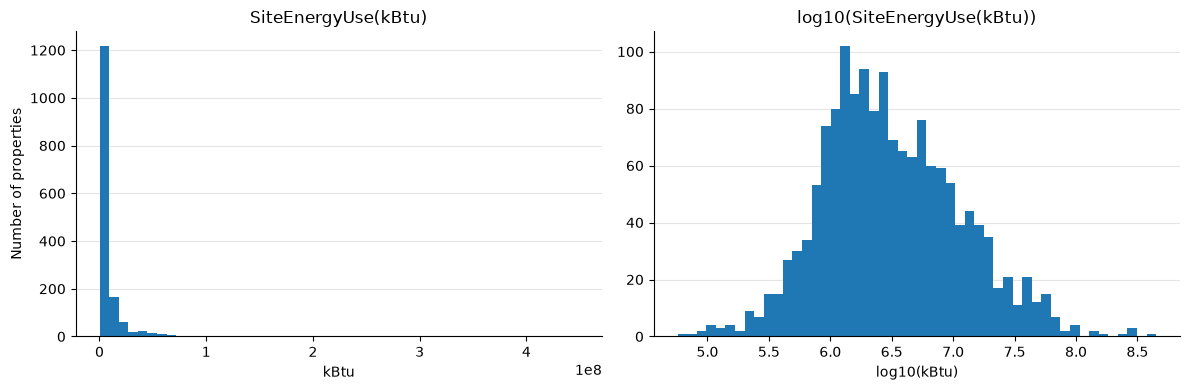

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=50)
axes[0].set_title(f"{TARGET}")
axes[0].set_xlabel("kBtu")
axes[0].set_ylabel("Number of properties")

axes[1].hist(np.log10(y), bins=50)
axes[1].set_title(f"log10({TARGET})")
axes[1].set_xlabel("log10(kBtu)")

plt.tight_layout()
plt.show()

The mean is about 3 times the median, so the "average" property is not representative and the distribution is highly skewed.

We will model log10 of the target. Its distribution is nearly symmetric, and the model then learns relative errors instead of chasing the largest properties. The predictions are converted back to kBtu, so that the metrics stay meaningful for the city.

In [31]:
threshold = y.quantile(0.9)
top_decile = y[y >= threshold]
print(
    f"The {len(top_decile)} largest properties (top 10%, >= {threshold:,.0f} kBtu) "
    f"account for {top_decile.sum() / y.sum():.1%} of the total energy use"
)

The 154 largest properties (top 10%, >= 17,728,764 kBtu) account for 57.7% of the total energy use


Energy use is highly concentrated: the 10% largest consumers account for about 58% of the total. They consume a lot mostly because they are large, not necessarily because they waste energy. To compare properties, we need the EUI, which we look at below.

This concentration is another reason to model log10 of the target. On the raw scale, a few properties would dominate the errors.

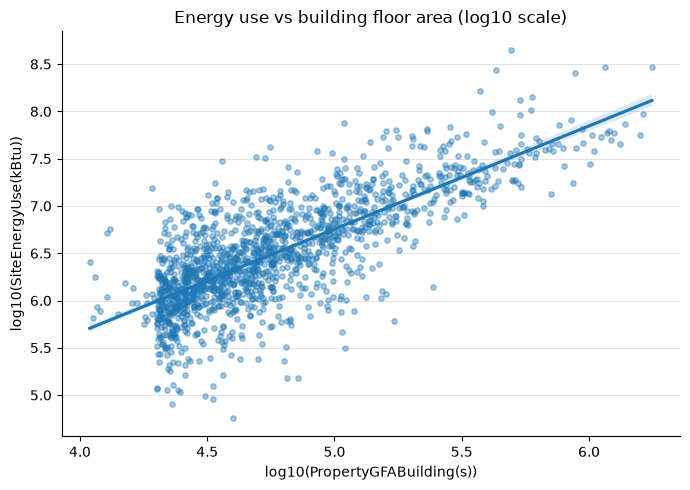

Pearson correlation (log10 scales): 0.76


In [32]:
AREA = "PropertyGFABuilding(s)"

log_data = pd.DataFrame(
    {
        f"log10({AREA})": np.log10(df[AREA]),
        f"log10({TARGET})": np.log10(df[TARGET]),
    }
)

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(
    data=log_data,
    x=log_data.columns[0],
    y=log_data.columns[1],
    scatter_kws={"s": 15, "alpha": 0.4},
    ax=ax,
)
ax.set_title("Energy use vs building floor area (log10 scale)")
plt.tight_layout()
plt.show()

print(
    f"Pearson correlation (log10 scales): {log_data[log_data.columns[0]].corr(log_data[log_data.columns[1]]):.2f}"
)

Energy use grows with building area, roughly along a straight line on log10 scales (Pearson 0.76). The spread is large, though: at equal area, energy use can vary a lot. Area is the main driver, but not the only one.

The sharp left edge around 20,000 sq ft is the threshold of the city's benchmarking program ([source](https://www.seattle.gov/environment/climate-change/buildings-and-energy/energy-benchmarking/)). It is a data collection rule, so the model will not be valid for smaller buildings.

### EUI by property type

The EUI is the energy use per sq ft of building, in kBtu/sq ft. Boxes show the quartiles, and whiskers extend to 1.5 times the interquartile range.

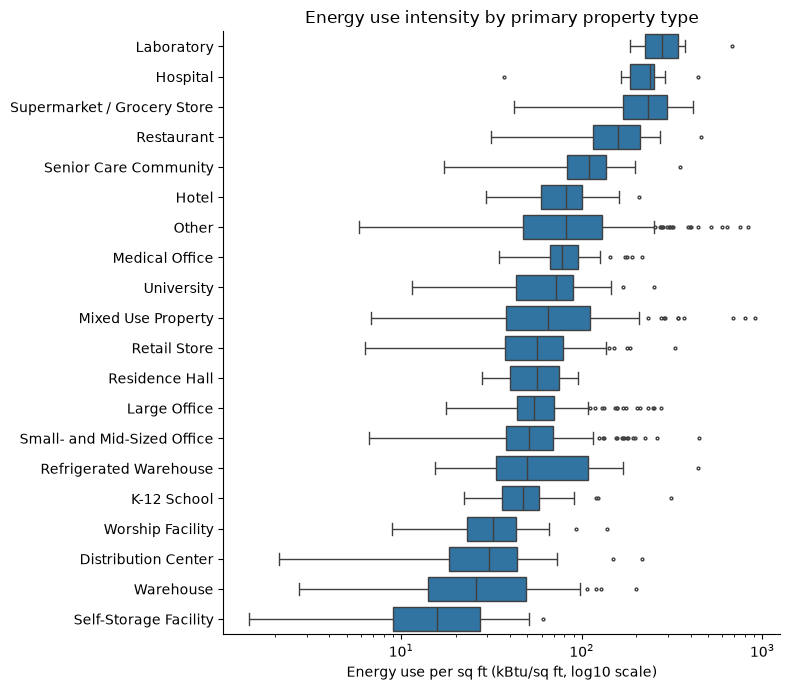

In [33]:
# Energy use intensity: energy use per square foot of building area (parking excluded)
intensity = df[TARGET] / df["PropertyGFABuilding(s)"]

order = (
    intensity.groupby(df["PrimaryPropertyType"]).median().sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 7))
sns.boxplot(
    x=intensity,
    y=df["PrimaryPropertyType"],
    order=order.index,
    fliersize=2,
    ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("Energy use per sq ft (kBtu/sq ft, log10 scale)")
ax.set_ylabel("")
ax.set_title("Energy use intensity by primary property type")
plt.tight_layout()
plt.show()

Laboratories, hospitals, supermarkets and restaurants are the most energy-intensive types. Warehouses, distribution centers and self-storage use the least. Laboratories and hospitals have only 10 properties each, so their boxes are less reliable.

The boxes are clearly shifted from one type to another, so the type carries real information about the EUI. But they are wide and overlap a lot, especially for `Other` and `Mixed Use Property`. The type is a useful feature, but not sufficient alone.

### EUI by neighborhood

Same boxplot, by neighborhood.

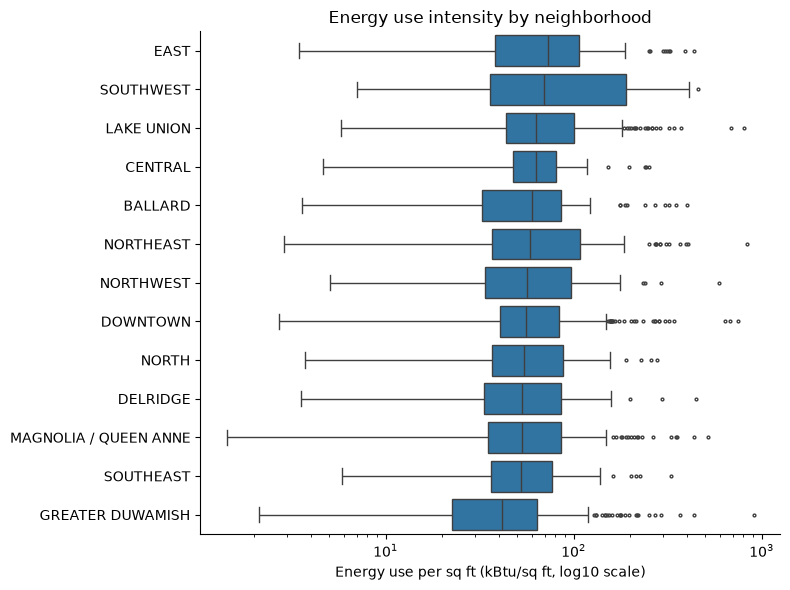

In [34]:
order = intensity.groupby(df["Neighborhood"]).median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(
    x=intensity,
    y=df["Neighborhood"],
    order=order.index,
    fliersize=2,
    ax=ax,
)
ax.set_xscale("log")
ax.set_xlabel("Energy use per sq ft (kBtu/sq ft, log10 scale)")
ax.set_ylabel("")
ax.set_title("Energy use intensity by neighborhood")
plt.tight_layout()
plt.show()

The neighborhoods are much closer to each other than the property types. The exception is Greater Duwamish, the industrial area, where warehouses and distribution centers are concentrated.

The neighborhood says little by itself. What it seems to show is mostly the mix of property types. It is at best a secondary feature.

### EUI by construction year

Each point is a property. The line shows the median per decade.

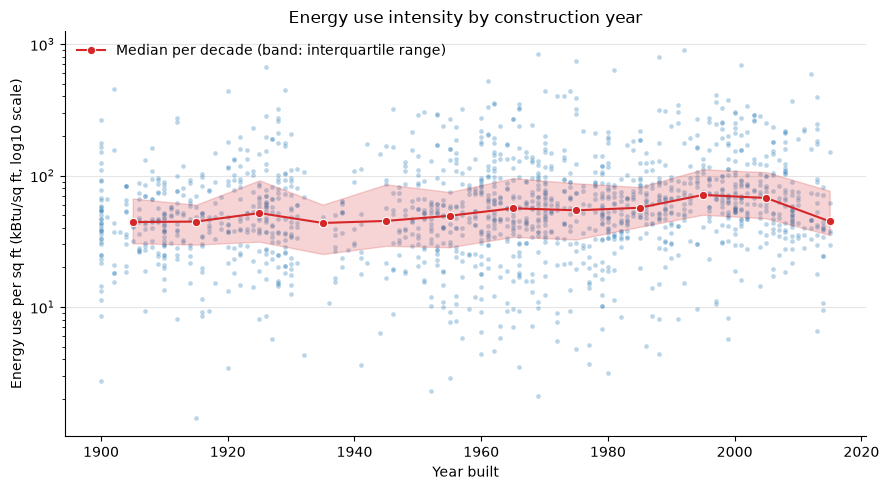

In [35]:
year_eui = pd.DataFrame(
    {
        "YearBuilt": df["YearBuilt"],
        "decade": df["YearBuilt"] // 10 * 10 + 5,  # center of the decade
        "eui": intensity,
    }
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=year_eui, x="YearBuilt", y="eui", s=12, alpha=0.3, ax=ax)
sns.lineplot(
    data=year_eui,
    x="decade",
    y="eui",
    estimator="median",
    errorbar=("pi", 50),
    color="C3",
    marker="o",
    label="Median per decade (band: interquartile range)",
    ax=ax,
)
ax.set_yscale("log")
ax.set_xlabel("Year built")
ax.set_ylabel("Energy use per sq ft (kBtu/sq ft, log10 scale)")
ax.set_title("Energy use intensity by construction year")
plt.tight_layout()
plt.show()

The trend is weak. The median EUI stays between about 44 and 71 kBtu/sq ft from one decade to the next. The spread within a decade is much larger than the differences between decades. The construction year is a weak feature on its own. It may help as a construction period, built during the feature engineering.

## 5. Summary

We keep 1,535 of the 1,656 non-residential properties (93%). Each filtering step follows a rule of the city or a check against its records.

The target is highly skewed: the mean is three times the median, and the 10% largest consumers account for 58% of the total. We will model log10 of the target and compute the metrics in kBtu.

Floor area is the main driver of energy use. The property type comes second: it shifts the EUI, but with a wide spread within each type. The neighborhood and the construction year matter much less.

The data only covers buildings over 20,000 sq ft, so the model will not be valid for smaller ones.

## 6. Save the cleaned dataset

We save the cleaned dataset in Parquet format, which keeps the column types. Notebook 02 loads it.

In [36]:
from pathlib import Path

PROCESSED_PATH = Path("../data/processed/buildings_cleaned.parquet")
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)

df.to_parquet(PROCESSED_PATH)
print(f"Saved {df.shape[0]} rows x {df.shape[1]} columns to {PROCESSED_PATH}")

Saved 1535 rows x 13 columns to ../data/processed/buildings_cleaned.parquet
